In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

# Create a Representative Dataset
np.random.seed(42)
n_rows = 200

data = {
    'Employee_ID': range(101, 101 + n_rows),
    'Age': np.random.randint(22, 60, size=n_rows),
    'Experience_Years': np.random.randint(0, 35, size=n_rows),
    'Monthly_Salary_USD': np.random.normal(5500, 1500, size=n_rows).round(2),
    'Performance_Score': np.random.randint(50, 100, size=n_rows),
    'Department': np.random.choice(['IT', 'HR', 'Sales', 'Finance', 'Marketing'], size=n_rows)
}

df = pd.DataFrame(data)

In [7]:

df.loc[10, 'Monthly_Salary_USD'] = np.nan
df.loc[25, 'Age'] = np.nan
df.loc[45, 'Performance_Score'] = np.nan
# Adding duplicate rows
df = pd.concat([df, df.iloc[[5, 12, 30]]], ignore_index=True)

print("Dataset Created! Shape:", df.shape)

Dataset Created! Shape: (203, 6)


In [8]:
# Task 1: Mean, Median, and Mode for 'Monthly_Salary_USD'
salary_clean = df['Monthly_Salary_USD'].dropna()

mean_salary = salary_clean.mean()
median_salary = salary_clean.median()
mode_salary = salary_clean.mode()[0]

print(" Task 1: Statistical Analysis")
print("Mean Monthly Salary: ${mean_salary:,.2f}")
print("Median Monthly Salary: ${median_salary:,.2f}")
print("Mode Monthly Salary: ${mode_salary:,.2f}")

 Task 1: Statistical Analysis
Mean Monthly Salary: ${mean_salary:,.2f}
Median Monthly Salary: ${median_salary:,.2f}
Mode Monthly Salary: ${mode_salary:,.2f}


In [9]:
# Task 2: Variance & Standard Deviation for 'Monthly_Salary_USD'
variance_salary = salary_clean.var()
std_salary = salary_clean.std()

print(" Task 2: Variance & Standard Deviation")
print("Salary Variance: {variance_salary:,.2f}")
print("Salary Standard Deviation: ${std_salary:,.2f}")

 Task 2: Variance & Standard Deviation
Salary Variance: {variance_salary:,.2f}
Salary Standard Deviation: ${std_salary:,.2f}


In [10]:
# Task 3: Correlation & Probability

corr_val = df['Experience_Years'].corr(df['Monthly_Salary_USD'])
print(" Task 3: Correlation & Probability ")
print("Correlation between Experience and Salary: {corr_val:.4f}")

it_employees = df[df['Department'] == 'IT']
it_high_earners = it_employees[it_employees['Monthly_Salary_USD'] > 6000]
prob = len(it_high_earners) / len(it_employees)
print("Probability of earning > $6000 given Department is IT: {prob:.2f} ({prob*100}%)")

 Task 3: Correlation & Probability 
Correlation between Experience and Salary: {corr_val:.4f}
Probability of earning > $6000 given Department is IT: {prob:.2f} ({prob*100}%)


In [11]:
# Task 3: Correlation & Probability
corr_val = df['Experience_Years'].corr(df['Monthly_Salary_USD'])
print(" Task 3: Correlation & Probability ")
print("Correlation between Experience and Salary: {corr_val:.4f}")

it_employees = df[df['Department'] == 'IT']
it_high_earners = it_employees[it_employees['Monthly_Salary_USD'] > 6000]
prob = len(it_high_earners) / len(it_employees)
print("Probability of earning > $6000 given Department is IT: {prob:.2f} ({prob*100}%)")

 Task 3: Correlation & Probability 
Correlation between Experience and Salary: {corr_val:.4f}
Probability of earning > $6000 given Department is IT: {prob:.2f} ({prob*100}%)


In [12]:
# Task 4: Outlier Detection using Interquartile Range (IQR) method
Q1 = salary_clean.quantile(0.25)
Q3 = salary_clean.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = salary_clean[(salary_clean < lower_bound) | (salary_clean > upper_bound)]
print(" Task 4: Outlier Detection ")
print("Lower Bound: {lower_bound:,.2f}, Upper Bound: {upper_bound:,.2f}")
print("Detected Outliers:\n{outliers}")

 Task 4: Outlier Detection 
Lower Bound: {lower_bound:,.2f}, Upper Bound: {upper_bound:,.2f}
Detected Outliers:
{outliers}


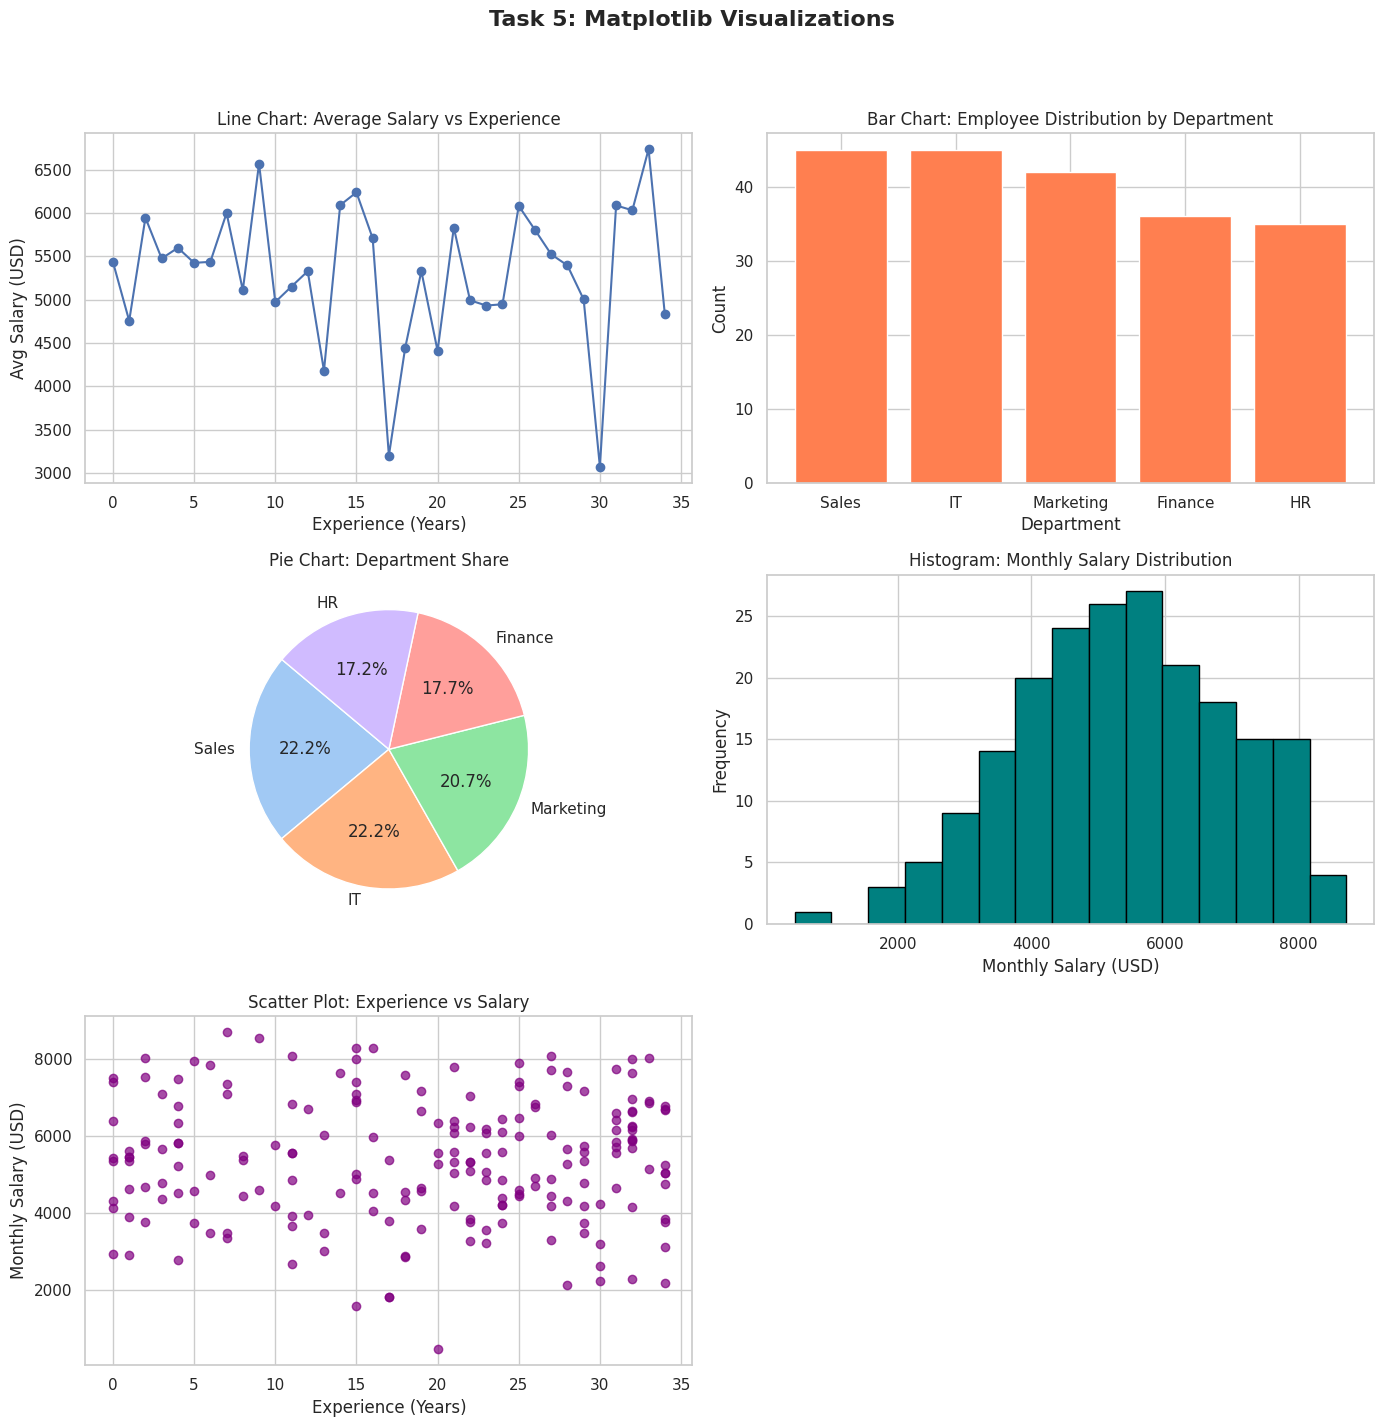

In [13]:
# Task 5: Matplotlib Visualizations
fig, axes = plt.subplots(3, 2, figsize=(14, 15))
fig.suptitle("Task 5: Matplotlib Visualizations", fontsize=16, fontweight='bold')

# 1. Line Chart: Average Salary by Experience Years
exp_salary = df.groupby('Experience_Years')['Monthly_Salary_USD'].mean()
axes[0, 0].plot(exp_salary.index, exp_salary.values, marker='o', color='b', linestyle='-')
axes[0, 0].set_title("Line Chart: Average Salary vs Experience")
axes[0, 0].set_xlabel("Experience (Years)")
axes[0, 0].set_ylabel("Avg Salary (USD)")

# 2. Bar Chart: Employee Count by Department
dept_counts = df['Department'].value_counts()
axes[0, 1].bar(dept_counts.index, dept_counts.values, color='coral')
axes[0, 1].set_title("Bar Chart: Employee Distribution by Department")
axes[0, 1].set_xlabel("Department")
axes[0, 1].set_ylabel("Count")

# 3. Pie Chart: Department Share
axes[1, 0].pie(dept_counts.values, labels=dept_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("pastel"))
axes[1, 0].set_title("Pie Chart: Department Share")

# 4. Histogram: Salary Distribution
axes[1, 1].hist(salary_clean, bins=15, color='teal', edgecolor='black')
axes[1, 1].set_title("Histogram: Monthly Salary Distribution")
axes[1, 1].set_xlabel("Monthly Salary (USD)")
axes[1, 1].set_ylabel("Frequency")

# 5. Scatter Plot: Experience vs Salary
axes[2, 0].scatter(df['Experience_Years'], df['Monthly_Salary_USD'], alpha=0.7, color='purple')
axes[2, 0].set_title("Scatter Plot: Experience vs Salary")
axes[2, 0].set_xlabel("Experience (Years)")
axes[2, 0].set_ylabel("Monthly Salary (USD)")
axes[2, 1].axis('off') # hide unused subplot

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

/tmp/ipykernel_1518/1903425242.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Department', ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_1518/1903425242.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Department', y='Monthly_Salary_USD', ax=axes[0, 1], palette='Set3')


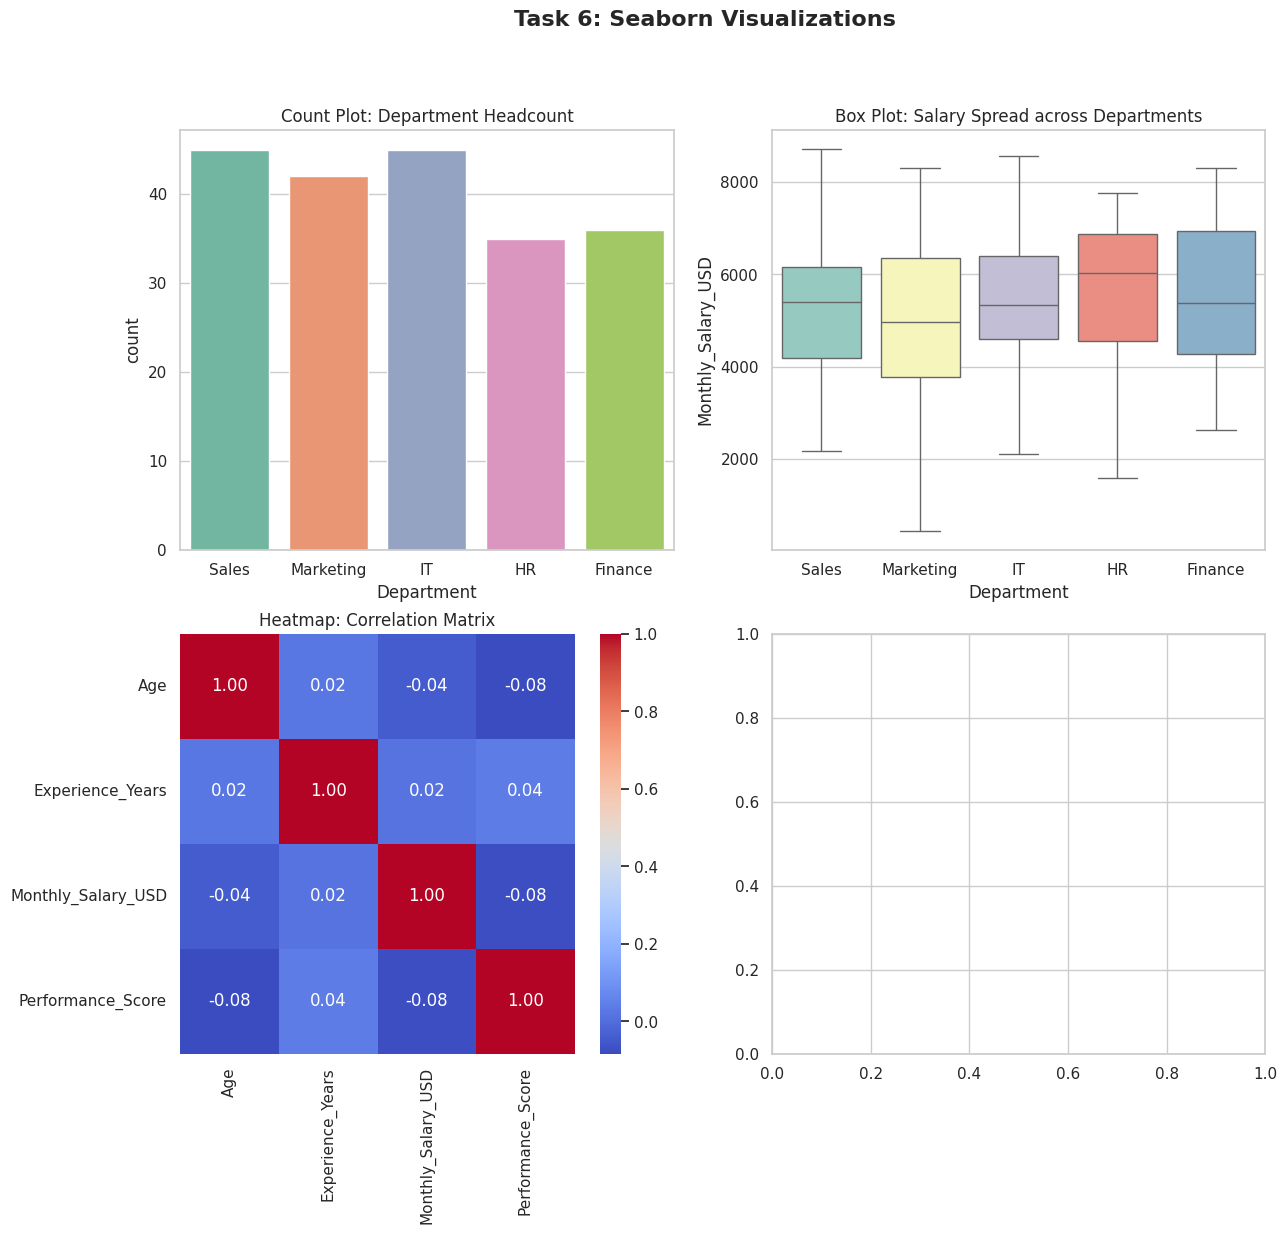

<Figure size 800x800 with 0 Axes>

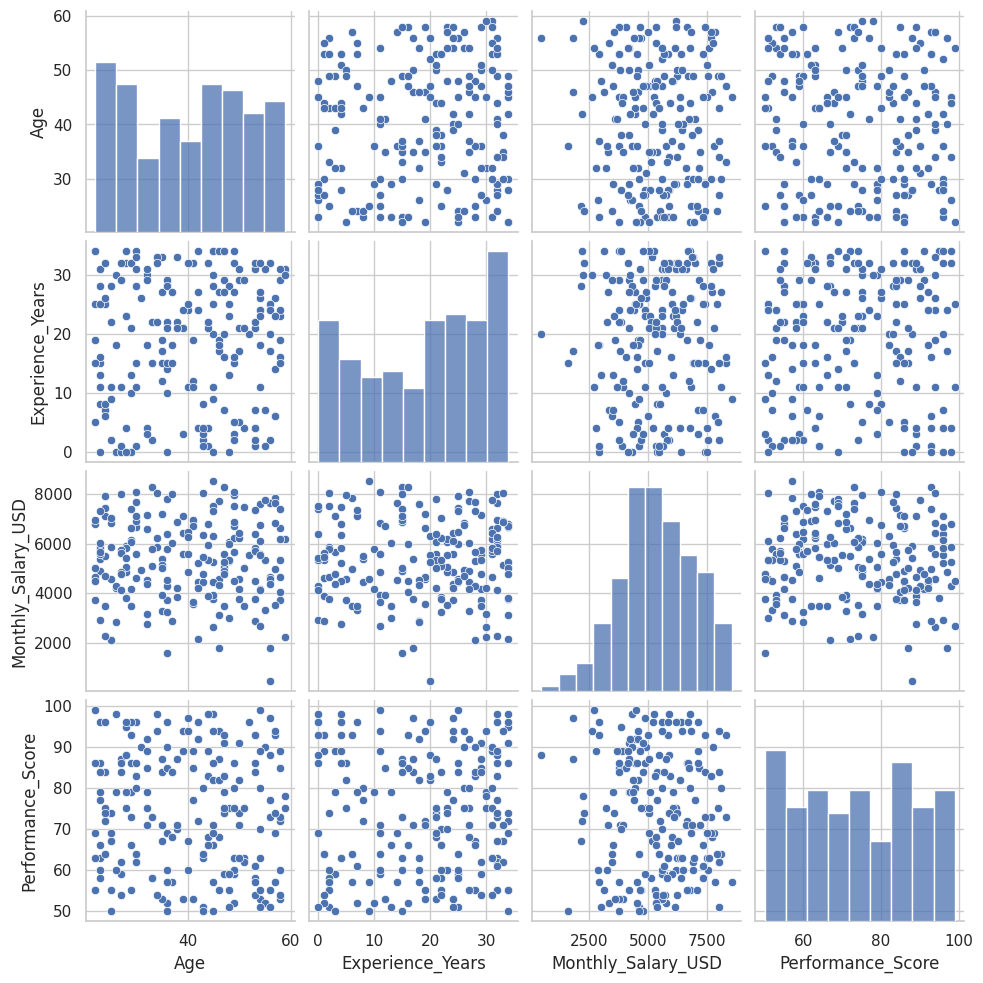

In [14]:
# Task 6: Seaborn Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Task 6: Seaborn Visualizations", fontsize=16, fontweight='bold')

# Count Plot
sns.countplot(data=df, x='Department', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title("Count Plot: Department Headcount")

# Box Plot
sns.boxplot(data=df, x='Department', y='Monthly_Salary_USD', ax=axes[0, 1], palette='Set3')
axes[0, 1].set_title("Box Plot: Salary Spread across Departments")

# Heatmap (Correlation Matrix)
numeric_df = df[['Age', 'Experience_Years', 'Monthly_Salary_USD', 'Performance_Score']].dropna()
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1, 0])
axes[1, 0].set_title("Heatmap: Correlation Matrix")

# Pair Plot
plt.figure(figsize=(8, 8))
sns.pairplot(numeric_df)
plt.show()

In [15]:
# Task 7: EDA - Inspection & Cleaning
print(" BEFORE CLEANING ")
print("Shape: {df.shape}")
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Count:", df.duplicated().sum())


 BEFORE CLEANING 
Shape: {df.shape}
Missing Values:
 Employee_ID           0
Age                   1
Experience_Years      0
Monthly_Salary_USD    1
Performance_Score     1
Department            0
dtype: int64
Duplicate Count: 3


In [16]:
# Clean data
df['Monthly_Salary_USD'].fillna(df['Monthly_Salary_USD'].median(), inplace=True)
df['Age'].fillna(df['Age'].median(), inplace=True)
df['Performance_Score'].fillna(df['Performance_Score'].mean(), inplace=True)
df.drop_duplicates(inplace=True)

print(" AFTER CLEANING ")
print("Shape: {df.shape}")
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Count:", df.duplicated().sum())

 AFTER CLEANING 
Shape: {df.shape}
Missing Values:
 Employee_ID           0
Age                   0
Experience_Years      0
Monthly_Salary_USD    0
Performance_Score     0
Department            0
dtype: int64
Duplicate Count: 0


/tmp/ipykernel_1518/2629578332.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Monthly_Salary_USD'].fillna(df['Monthly_Salary_USD'].median(), inplace=True)
/tmp/ipykernel_1518/2629578332.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].me